## CS328 Assignment 2: Human Activity Recognition Using Machine Learning

The objective of this assignment is to develop your understanding and practical application skills in the field of machine learning, particularly focusing on Human Activity Recognition (HAR). Human Activity Recognition has become increasingly important in various fields including health care, personal fitness, smart homes, and surveillance. In this assignment, you will be working with the accelerometer data the class collected with Sensor Logger in the Activities Study, plus a small sample dataset recorded with a wrist-worn device. The data has been classified into seven distinct activities: walking, walking downstairs, running/jogging, lying, sitting, standing, and walking upstairs.

You will get hands-on experience in several key aspects of machine learning and data processing:
1. Data collection and preprocessing from multiple sources for analysis
2. Understand how to create windows of raw data through resampling and to extract meaningful features from these windows.
3. Hands-on experience on how to extract features, encode target variables, split datasets, train models, make predictions, and evaluate the performance of these models.
4. Learn to assess your trained model’s performance using common metrics like accuracy, confusion matrix and more. Understanding how well your models are performing is crucial in any machine learning task.

Through this assignment, you will be able to develop a pipeline for Human Activity Recognition that can be further fine-tuned for different tasks or datasets. You will be able to apply the skills and knowledge gained here to other machine learning projects and real-world applications.

#### Imports Block

Make sure all imports are in this block below (and leave the two comments IMPORTS START and IMPORT END as is. The extractor script uses the START and END delimitors when extracting the functions).

In [1]:
# -- IMPORTS START --
import pandas as pd
import glob
import re
import os
import sys
import pickle
import datetime
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime
from sklearn import tree, metrics
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from scipy.signal import butter, filtfilt, find_peaks
from sklearn.tree import DecisionTreeClassifier,export_graphviz
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from util import viz_tree, calc_magnitude, remove_noise, add_features
# -- IMPORTS END --

# enable zooming into graphs
%matplotlib inline
plt.rcParams['figure.figsize'] = [9, 6] # width, height in inches

#### About the data (read this before you start)

- **Class_Data** was recorded with Sensor Logger. Its `Accelerometer` sensor reports **linear acceleration in m/s² with gravity removed**: the phone combines the accelerometer and gyroscope to estimate the gravity vector and subtracts it from the raw signal. A phone lying still on a table reads ≈ 0 on all three axes, not 9.8.
- **Sample_Data** was recorded with a wrist-worn device. It has already been converted to match Class_Data (from *g* to m/s², and gravity removed), so both datasets are in the same units.
- Most phones log at ~100 Hz, but a few class recordings are at 50-60 Hz. Estimate the sampling rate of each file from its timestamps instead of hard-coding it.
- The column order differs between the two folders (`time,x,y,z` vs `time,seconds_elapsed,z,y,x`), so always select columns by name.

**Hint (why gravity matters):** with gravity removed, the orientation of the phone is lost. Lying, sitting, and standing all look like "almost no motion", so features computed on the acceleration magnitude will confuse them. Think about what is still different between these activities (e.g., how much the body sways while standing) and expect some confusion between these three classes. Walking, stairs, and jogging differ in intensity and rhythm, so frequency-domain and per-axis features are worth trying.

###  Assignment: Function 1: extract_features(data, window_sec, sample_rate, activity)

**Instructions:**
Define the `extract_features` function that extracts features from accelerometer data by applying a sliding window approach.


**Hints and Instructions:**
Use the `pandas.DataFrame.resample` function to implement the sliding window approach (it needs the time as index: `data.set_index('time').resample(f'{window_sec}s')`). Remember to use the computed features when appending to the new DataFrame.

- The function takes as arguments:
  - `data`: a DataFrame containing the `time` column, the raw `x`, `y`, `z` axes, and the filtered acceleration magnitude signal
  - `window_sec`: the window length in seconds for feature extraction
  - `sample_rate`: the sampling frequency of the accelerometer data
  - `activity`: the activity label for each window you extract
- The function will perform the following:
  - For each window in the resampled data:
    - Skip windows that are too short (e.g., fewer than 80% of `window_sec * sample_rate` samples). These are the partial windows at the start and end of a recording, or gaps in the logging.
    - Call the `add_my_features` function (Function 3) to compute features of the window
    - Add the `activity` label to the features
  - Append the computed features to a new DataFrame and return this DataFrame

In [2]:
# Function to extract windows and features
def extract_features(data, window_sec, sample_rate, activity):
    
    ######## TODO ###############
    features_df = pd.DataFrame()

    # Set the minimum number of samples required per window
    min_samples = 0.8 * window_sec * sample_rate

    # Set time as the index and split data into windows
    windows = data.set_index('time').resample(f'{window_sec}s')

    # Extract features from each window
    for _, window in windows:
        # Skip windows that are too short
        if len(window) < min_samples:
            continue

        # Calculate features for the current window
        features = add_my_features(window, sample_rate)

        # Add the activity label
        features['activity'] = activity

        # Append features to the results DataFrame
        features_df = pd.concat(
            [features_df, features],
            ignore_index=True
        )

    #############################
    
    return features_df

###  Assignment: Function 2: all_data_to_combined_csv(root, output_filename, window_sec)

This function is expected to process data collected from different activities, extract features and store everything into a combined CSV file.

**Hint and Instructions:**
Understand how the `glob`, `pandas` and `os` modules work. Understand how the `calc_magnitude` and `remove_noise` function work. The activity label is the name of the folder that contains the file, so use `os.path.basename(os.path.dirname(filename))` to extract the activity (file names such as `026.csv` or `accelerometer_<date>.csv` do not contain it).

- Write a function named `all_data_to_combined_csv(root, output_filename, window_sec)`.
- This function will process the data collected from various activities such as walking downstairs, jogging, lying, sitting, standing, walking upstairs, and walking. These activities' data are stored in different .csv files within their respective folders.
- the `root` will be the root folder of all the files.
- the `output_filename` will be the filename of the combined csv file.
- the `window_sec` will be the window length in seconds, so that you can try different window lengths.
- Use the glob module to create a list of all .csv files from each activity's directory.
- The pandas DataFrame `all_data` is initialized to store the processed data from all activities.
- The function will then loop over each activity's data file. For each file:
    - read each .csv file into a pandas DataFrame. `pd.read_csv` loads the `time` column as text, so parse it with `parse_dates=['time']` (this works once `transform_time_to_datetime` below has converted the Class_Data timestamps).
    - estimate the sampling rate of the file from its timestamps.
    - From the raw data, calculate the magnitude and remove any noise.
    - Extract the activity type for each file.
    - extract features using the `extract_features()` function.
    - add a `recording` column with the file name, so that windows can be grouped back into recordings later (majority vote and failure analysis).
    - append the feature frames into the all_data dataframe.
- Continue this process until all .csv files from all activities have been processed.
- Finally, the function writes the `all_data` DataFrame to `output_filename` and returns it.

In [3]:
def all_data_to_combined_csv(root, output_filename, window_sec):
    # Initialize a DataFrame to store all extracted features
    all_data = pd.DataFrame()

    # Find all CSV files in the root folder and its subfolders
    files = glob.glob(os.path.join(root, '**', '*.csv'), recursive=True)

    # Process each file
    for filename in files:
        # Read the CSV file
        data = pd.read_csv(filename)

        # REVISION: Class_Data stores time as nanoseconds, while Sample_Data stores
        # formatted datetimes. The original loader assumed one timestamp format.
        # Converting here fixes the sampling-rate calculation without changing
        # the source CSV files.
        if pd.api.types.is_numeric_dtype(data['time']):
            data['time'] = pd.to_datetime(data['time'], unit='ns', utc=True).dt.tz_localize(None)
        else:
            data['time'] = pd.to_datetime(data['time'], errors='coerce')

        data = data.dropna(subset=['time'])

        # Estimate the sampling rate from timestamps
        time_diff = data['time'].diff().dt.total_seconds().median()
        if pd.isna(time_diff) or time_diff <= 0:
            continue

        sample_rate = 1 / time_diff

        # Calculate acceleration magnitude
        data = calc_magnitude(data)

        # Remove noise using a low-pass filter
        data = remove_noise(data, sample_rate)

        # Extract the activity label from the parent folder name
        activity = os.path.basename(os.path.dirname(filename))

        # Extract features from each time window
        features = extract_features(data, window_sec, sample_rate, activity)

        # Add the recording filename
        features['recording'] = os.path.basename(filename)

        # Append the extracted features
        all_data = pd.concat([all_data, features], ignore_index=True)

    # Save only the combined feature table, not the source recordings
    all_data.to_csv(output_filename, index=False)

    return all_data

###  Assignment: Function 3: add_my_features(window, sample_rate)

This is where you do your **feature engineering** (exploration report §1). The function receives one window and returns a one-row DataFrame of features.

**Hints and Instructions:**
- Start from the baseline features in `add_features` (7 statistics of the filtered magnitude, from util.py) and add your own as new columns. As provided, the function only returns the baseline, so you can run the whole notebook before writing any features.
- Ideas to try:
  - Time domain: RMS, range, interquartile range, zero-crossing rate, number of peaks per second (`find_peaks`)
  - Frequency domain: dominant frequency and spectral energy in a band (use `np.fft.rfft` on the filtered magnitude and `np.fft.rfftfreq(len(signal), 1/sample_rate)`)
  - Per axis: standard deviation of `x`, `y`, `z`, or correlation between axes
- Aim for ~5-8 features in your final pipeline. Keep the ones that help and document the ones you dropped.

In [4]:
def add_my_features(window, sample_rate):
    # Start with the 7 baseline features
    features = add_features(window)

    # Get the filtered acceleration magnitude
    signal = window['filtered_accel_mag'].to_numpy()
    signal = signal[~np.isnan(signal)]

    # Return baseline features if there is insufficient data
    if len(signal) < 2:
        return features

    # Time-domain features
    # 1. Root Mean Square (RMS)
    features['rms'] = np.sqrt(np.mean(signal ** 2))

    # 2. Range
    features['range'] = np.max(signal) - np.min(signal)

    # 3. Interquartile Range (IQR)
    features['iqr'] = np.percentile(signal, 75) - np.percentile(signal, 25)

    # 4. Zero-crossing rate
    features['zero_crossing_rate'] = np.mean(
        np.diff(np.signbit(signal))
    )

    # 5. Number of peaks per second
    peaks, _ = find_peaks(signal)
    duration = len(signal) / sample_rate
    features['peaks_per_sec'] = len(peaks) / duration if duration > 0 else 0

    # Frequency-domain feature
    # 6. Dominant frequency, excluding 0 Hz
    centered_signal = signal - np.mean(signal)
    fft_values = np.abs(np.fft.rfft(centered_signal))
    frequencies = np.fft.rfftfreq(
        len(centered_signal), d=1 / sample_rate
    )

    if len(fft_values) > 1:
        dominant_idx = np.argmax(fft_values[1:]) + 1
        features['dominant_freq'] = frequencies[dominant_idx]
    else:
        features['dominant_freq'] = 0.0

    return features


## Assignment: Transform time to datetime


Due to the fact that sensor logger data has a UTC time in nanoseconds instead of datetime, we should transform the time first. Feel free to modify the below function so that all the collected data has the same datetime format as the provided data. Check the Sample_Data folder to see the format we need.

Note that each activity data is in its own folder. For example, the collected downstairs data is in `data/Class_Data/downstairs`.

In [5]:
def transform_time_to_datetime(root):
    # REVISION: the original version saved converted data back over each source
    # CSV. Conversion now happens in all_data_to_combined_csv instead. This is a
    # read-only status check so the notebook structure remains familiar.
    files = glob.glob(os.path.join(root, '**', '*.csv'), recursive=True)
    print(f"Found {len(files)} files. No source files were changed.")

In [6]:
transform_time_to_datetime('./data/Class_Data')

Found 615 files. No source files were changed.


#### Helper functions (provided)

`train_decision_tree` and `evaluate` take an optional `features` argument (a list of column names). By default, `train_decision_tree` uses every feature column, i.e., everything except `activity` and `recording`, and `evaluate` uses the same columns the model was trained on.

In [7]:
BASELINE_FEATURES = ['avg', 'max', 'med', 'min', 'q25', 'q75', 'std']

def feature_columns(frames):
    return [c for c in frames.columns if c not in ('activity', 'recording')]


def evaluate(model, frames, features=None):
    # By default, use the same columns the model was trained on
    if features is None:
        features = getattr(model, 'feature_names_in_', feature_columns(frames))
    X_test = frames[list(features)]

    # Extract target column
    y_test = frames['activity']

    pred = model.predict(X_test)
    # Evaluate on test set
    acc = model.score(X_test, y_test)
    print(classification_report(y_test, pred, zero_division=0))
    print("Accuracy on test set:", acc)
    return acc, pred

In [8]:
def train_decision_tree(frames, max_depth=5, criterion='entropy', features=None):
    # Extract feature columns
    if features is None:
        features = feature_columns(frames)
    X = frames[list(features)]

    # Extract target column
    y = frames['activity']

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    # Create model
    dt_model = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth, random_state=42).fit(X_train, y_train)
    dt_pred = dt_model.predict(X_test)

    # Evaluate on test set
    acc = dt_model.score(X_test, y_test)
    dt_cm = confusion_matrix(y_test, dt_pred, labels=dt_model.classes_)
    print(classification_report(y_test, dt_pred, zero_division=0))
    print("Accuracy on test set:", acc)

    return dt_model,dt_cm,acc

## Assignment-Feature Exploration: Window Length and Features (Class_Data)

Before comparing models, choose the window length and the feature set (the **feature engineering** axis in RUBRIC.md, exploration report §1). Use only the class corpus and the 30% test split that `train_decision_tree` returns, with its default hyperparameters.

1. **Window length**: Build the class corpus with at least three window lengths (e.g., 2 s, 5 s, 10 s) and train `train_decision_tree` on each, using only the baseline features (`features=BASELINE_FEATURES`).

2. **Features**: Write `add_my_features` (Function 3) and rebuild the class corpus. Compare the baseline features to your features at the same window length. Try adding and removing features (pass `features=[...]` to `train_decision_tree`) and use the classification report to see which classes each feature helps.

3. **Lock in** one window length and one feature set, and use them in all the sections below.

4. **Fill up** this table.

5. **Interpretation of the results**: Which window length worked best, and why do you think so? Which features helped, and which class pairs did they separate? Which classes are still confused?

In [9]:
# Hints, step by step:
# Build the class corpus with different window lengths, e.g. all_data_to_combined_csv('./data/Class_Data', 'class_2s.csv', window_sec=2)
# Train train_decision_tree on each with features=BASELINE_FEATURES and compare the accuracy
# Write add_my_features, rebuild, and compare baseline vs your features at the same window length
# Lock in WINDOW_SEC and FEATURES for the rest of the notebook

########################### TODO ##########################
BASELINE_FEATURES = ['avg', 'max', 'med', 'min', 'q25', 'q75', 'std']

window_lengths = [2, 5, 10]
window_results = []
class_corpora = {}

for window_sec in window_lengths:
    print(f"\n{'='*40}")
    print(f"Window length: {window_sec} seconds")
    print(f"{'='*40}")

    # Build the class corpus
    class_data = all_data_to_combined_csv(
        './data/Class_Data',
        f'class_{window_sec}s.csv',
        window_sec
    )

    # Train and evaluate using baseline features
    model, cm, accuracy = train_decision_tree(
        class_data,
        features=BASELINE_FEATURES
    )

    window_results.append({
        'Window Length (s)': window_sec,
        'Number of Windows': len(class_data),
        'Accuracy': accuracy
    })

window_results_df = pd.DataFrame(window_results)
print("\nWindow Length Comparison:")
print(window_results_df.to_string(index=False))



Window length: 2 seconds
              precision    recall  f1-score   support

  downstairs       0.37      0.39      0.38       438
     jogging       0.79      0.77      0.78       282
       lying       0.53      0.08      0.14       511
     sitting       0.64      0.80      0.71      1158
    standing       0.52      0.64      0.58       596
    upstairs       0.00      0.00      0.00       444
        walk       0.47      0.74      0.58       748

    accuracy                           0.55      4177
   macro avg       0.47      0.49      0.45      4177
weighted avg       0.49      0.55      0.49      4177

Accuracy on test set: 0.5475221450802011

Window length: 5 seconds
              precision    recall  f1-score   support

  downstairs       0.32      0.59      0.42       169
     jogging       0.83      0.76      0.79       117
       lying       0.47      0.17      0.25       229
     sitting       0.65      0.71      0.68       404
    standing       0.46      0.72      

In [10]:

# Lock in the window length that gave the best baseline accuracy above
best_row = window_results_df['Accuracy'].idxmax()
WINDOW_SEC = int(window_results_df.loc[best_row, 'Window Length (s)'])
print("Best window length:", WINDOW_SEC, "s")

# Rebuild the class corpus with the features already written in add_my_features
class_frames = all_data_to_combined_csv(
    './data/Class_Data',
    'class_mine.csv',
    WINDOW_SEC
)
ALL_FEATURES = feature_columns(class_frames)

# REVISION: this is the same compact list already present in the original
# notebook; no new features were added.
MY_FEATURES = [
    'std',
    'range',
    'iqr',
    'zero_crossing_rate',
    'peaks_per_sec',
    'dominant_freq',
    'rms'
]

# REVISION: the original cell compared compact vs all, but did not include the
# provided baseline in this same comparison. Adding it makes the choice clear.
feature_sets = {
    'baseline (7 features)': BASELINE_FEATURES,
    'compact planned set (7 features)': MY_FEATURES,
    'all (baseline + mine)': ALL_FEATURES,
}

set_results = {}

for name, feats in feature_sets.items():
    print("=========== features:", name, "===========")

    model, cm, acc = train_decision_tree(
        class_frames,
        features=feats
    )

    set_results[name] = acc

# REVISION: the report discusses the provided baseline features. Remove one
# baseline feature at a time, as the assignment suggests, so the effect of each
# baseline feature is visible in the output.
baseline_accuracy = set_results['baseline (7 features)']
baseline_effect_rows = []

for feature in BASELINE_FEATURES:
    remaining_features = [
        name for name in BASELINE_FEATURES
        if name != feature
    ]

    _, _, accuracy_without_feature = train_decision_tree(
        class_frames,
        features=remaining_features
    )

    baseline_effect_rows.append({
        'feature': feature,
        'accuracy_without_feature': accuracy_without_feature,
        'feature_contribution':
            baseline_accuracy - accuracy_without_feature,
    })

baseline_effects_df = pd.DataFrame(baseline_effect_rows)

print("Baseline leave-one-feature-out results:")
print(baseline_effects_df.to_string(index=False))

# REVISION: test each feature already written in add_my_features by adding it
# individually to the baseline. This does not introduce any new features,
# models, or feature-selection methods.
feature_effect_rows = []

candidate_feature_sets = {
    'baseline (7 features)': BASELINE_FEATURES,
    'compact planned set (7 features)': MY_FEATURES,
}

for feature in [
    'rms',
    'range',
    'iqr',
    'zero_crossing_rate',
    'peaks_per_sec',
    'dominant_freq'
]:
    candidate_name = f'baseline + {feature} (8 features)'
    candidate_features = BASELINE_FEATURES + [feature]

    _, _, feature_accuracy = train_decision_tree(
        class_frames,
        features=candidate_features
    )

    set_results[candidate_name] = feature_accuracy
    candidate_feature_sets[candidate_name] = candidate_features

    feature_effect_rows.append({
        'feature': feature,
        'accuracy': feature_accuracy,
        'change_from_baseline':
            feature_accuracy - baseline_accuracy,
    })

feature_effects_df = pd.DataFrame(feature_effect_rows)
print(feature_effects_df.to_string(index=False))

# REVISION: choose the best result among only the existing 5–8-feature choices.
# The 13-feature set is still tested above, but it is not eligible for the final
# pipeline because the assignment asks for approximately 5–8 final features.
best_set = max(
    candidate_feature_sets,
    key=lambda name: set_results[name]
)

FEATURES = candidate_feature_sets[best_set]

print("Accuracy per feature set:", set_results)
print(
    "Locked in:",
    WINDOW_SEC,
    "s window, features:",
    best_set,
    FEATURES
)

Best window length: 2 s
=========== features: baseline (7 features) ===========
              precision    recall  f1-score   support

  downstairs       0.37      0.39      0.38       438
     jogging       0.79      0.77      0.78       282
       lying       0.53      0.08      0.14       511
     sitting       0.64      0.80      0.71      1158
    standing       0.52      0.64      0.58       596
    upstairs       0.00      0.00      0.00       444
        walk       0.47      0.74      0.58       748

    accuracy                           0.55      4177
   macro avg       0.47      0.49      0.45      4177
weighted avg       0.49      0.55      0.49      4177

Accuracy on test set: 0.5475221450802011
=========== features: compact planned set (7 features) ===========
              precision    recall  f1-score   support

  downstairs       0.40      0.07      0.12       438
     jogging       0.94      0.60      0.73       282
       lying       0.25      0.12      0.16       51

**For the data in the dataset:**

| Window length | Features | Accuracy (Class_Data test split) |
|-|-|-|
| 2 s | baseline | 0.547522|
| 5 s | baseline | 0.536934 |
| 10 s | baseline | 0.529491 |
| 2s | baseline + zero_crossing_rate (8 features, locked in) | 0.552071 |


#### 🛑 Interpretation of the results

The 2-second window achieved the highest accuracy among the three window lengths tested using the baseline features (54.75%), compared with 53.69% for 5 seconds and 52.95% for 10 seconds. The differences are small, but shorter windows performed slightly better on this dataset and also produce more windows (13,922 at 2 s) to train on, so a 2-second window was locked in.

At the 2-second window, I compared several feature sets. The baseline features achieved 54.75%, the compact set of seven added features (without the baseline statistics) achieved 50.47%, and all 13 features achieved 54.39%. Since the final pipeline should use about 5–8 features, the 13-feature set was not eligible, and I tested each added feature on top of the baseline instead. Adding `zero_crossing_rate` gave the best result (55.21%, +0.46 points), followed by `iqr` (54.87%, +0.12 points). `rms` made no difference (54.75%), while `range` (54.46%), `peaks_per_sec` (54.44%) and `dominant_freq` (54.39%) slightly lowered accuracy. The baseline plus `zero_crossing_rate` was therefore locked in as the final feature set.

The gains from the added features are very small (under half a percentage point, or about 20 of the 4,177 test windows), so they may be within noise. The main result is that the features I engineered did not improve accuracy much beyond the baseline statistics, and that adding more features does not necessarily help. The compact set performed worst because it dropped the baseline statistics, which suggests the intensity-based baseline features carry most of the useful signal.

## Assignment-Classification1: Testing Decision Tree Classifier Performance (Train: Sample_Data, Test: Class_Data)

In this section, we will evaluate the overall performance of our activity classifier using a combined dataset of all activities. This process helps understand how accurately the model can classify a wide variety of activities. The steps are as follows:

1. **Data Generation**: We start by calling the `all_data_to_combined_csv()` function with your chosen window length, for both Sample_Data and Class_Data. This function processes all the individual activity datasets, applies the necessary preprocessing, and generates a combined CSV file. If you change your preprocessing or features, call it again to rebuild the file.

2. **Data Loading**: Once we have the combined CSV file, we load it into a pandas DataFrame for further use (or use the DataFrame the function returns).

3. **Model Training**: The `train_decision_tree` function is then called. This function trains the decision tree model and evaluates its performance, printing the precision, recall, and accuracy metrics. It also returns the trained model, the confusion matrix, and the overall accuracy for further use. Train a model using sample data and evaluate it on the class corpus. Use the default hyper parameters in `train_decision_tree`.

4. **Grid Search**: Do grid search for tuning the hyperparameters (max_depth and criterion in `train_decision_tree`). Basically train models using sample data with different hyperparameters and pick the hyperparameters with the highest accuracy on the test split of the sample data (`train_decision_tree` returns it). Then evaluate the best model on the class corpus. Do not pick hyperparameters by looking at the class corpus accuracy: it is your test set. Finally report accuracy and hyperparameters as well.

5. **Performance Visualization**: To provide a visual understanding of the model's performance, we display the confusion matrix using matplotlib's `ConfusionMatrixDisplay` function. Each row of the matrix corresponds to a true class, while each column corresponds to a predicted class. The diagonal elements represent correctly classified instances, and off-diagonal elements are instances that are misclassified. Visualize the confusion matrix for the test set.

6. **Decision Tree Visualization**: Finally, visualize the decision tree using the `viz_tree` function (loaded from util.py). This function generates a graphic representation of the decision tree model (the top levels), showing how it makes decisions based on the features.

7. **Fill up** this table based on the results you obtain by trying different parameters (fill both rows). We will evaluate the accuracy of numbers you fill up below.

8. **Interpretation of the results**: What do these accuracy scores suggest about the ability of the model to distinguish between these activities? Do some activities appear to be more distinguishable than others? what did you learn from hyperparameter tuning? Remember to provide a brief discussion for each point.

This section's output can help understand how well the model generalizes to different activities and how different features influence the model's decisions. Also, you will see the effect of hyperparameter tuning. Remember that it's normal if the model performs better on some activities than others, depending on the complexity and distinctiveness of the activities.

              precision    recall  f1-score   support

  downstairs       0.45      0.73      0.55        56
     jogging       0.98      0.98      0.98       200
       lying       0.62      0.34      0.44       127
     sitting       0.62      0.92      0.74       141
    standing       0.72      0.65      0.68       124
    upstairs       0.38      0.59      0.46        56
        walk       0.91      0.45      0.61       130

    accuracy                           0.70       834
   macro avg       0.67      0.67      0.64       834
weighted avg       0.74      0.70      0.69       834

Accuracy on test set: 0.6990407673860911
              precision    recall  f1-score   support

  downstairs       0.29      0.56      0.39      1478
     jogging       0.66      0.80      0.72       950
       lying       0.22      0.34      0.27      1813
     sitting       0.58      0.39      0.47      3779
    standing       0.41      0.47      0.43      1966
    upstairs       0.28      0.29    

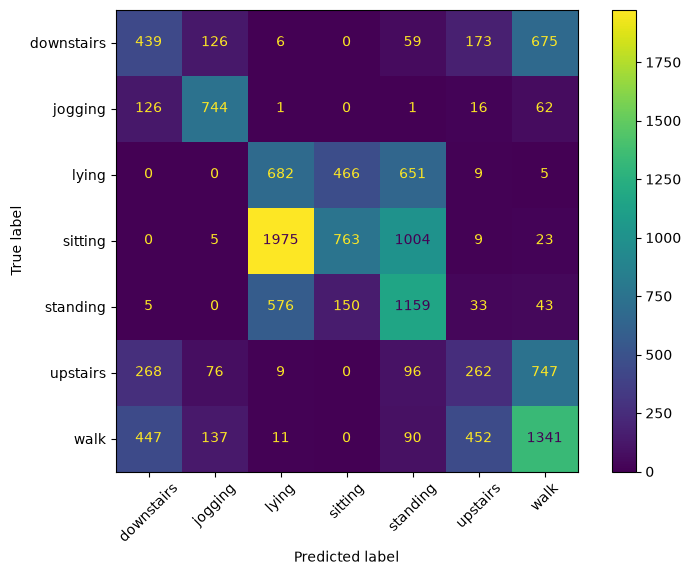

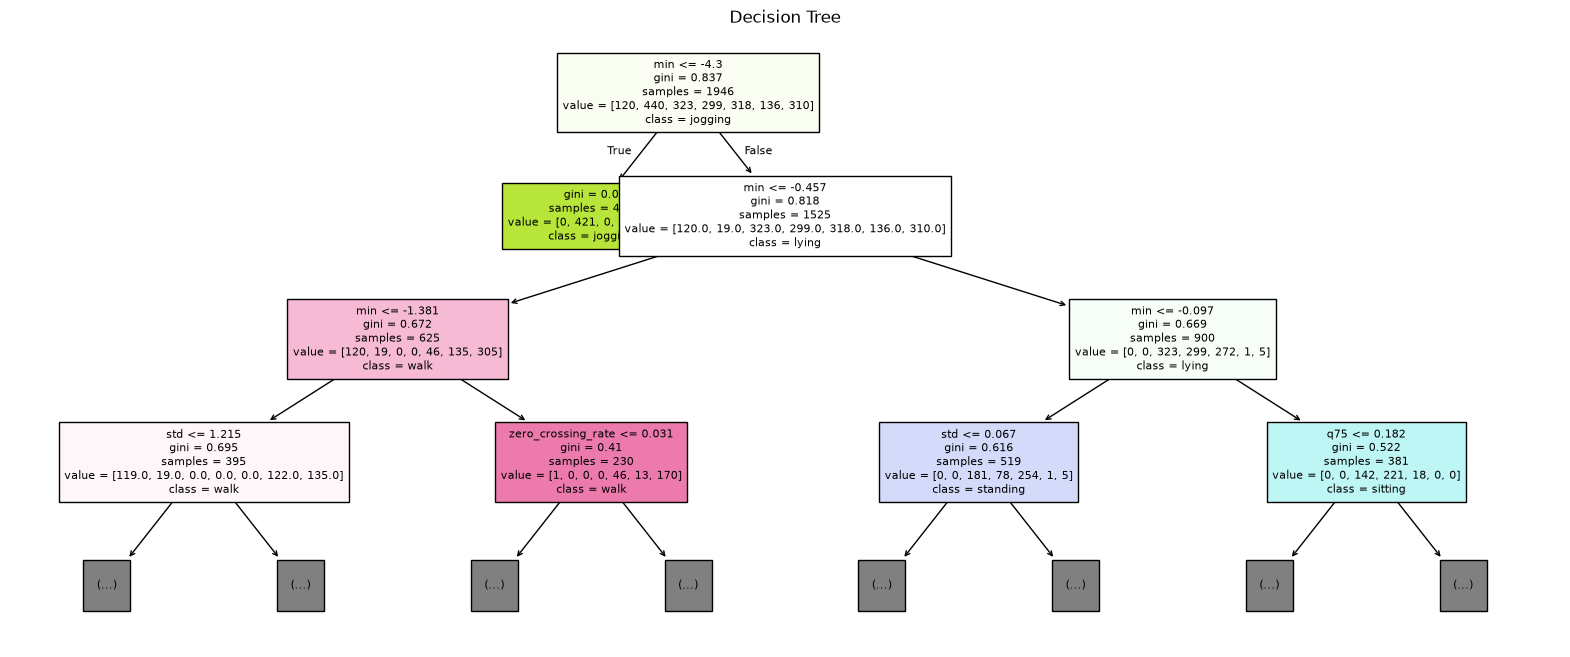

In [11]:
# Hints, step by step:
# Combine all the data under data/Sample_Data
# Combine all the data under data/Class_Data
# Train the decision tree
# Grid search, choosing by the Sample_Data test split accuracy
# Display the confusion matrix
# Visualize the tree
# Evaluate the model on class dataset

########################### TODO ##########################

import io, contextlib

# Helper: try many hyperparameters, choose by the test split of the TRAINING data only
def grid_search_tree(frames, features):
    best_acc, best_depth, best_crit = -1, None, None
    for depth in [3, 5, 7, 10, None]:
        for crit in ['gini', 'entropy', 'log_loss']:
            with contextlib.redirect_stdout(io.StringIO()):   # hide the long printing
                m, cm, acc = train_decision_tree(frames, max_depth=depth, criterion=crit, features=features)
            print("max_depth =", depth, " criterion =", crit, " accuracy =", round(acc, 4))
            if acc > best_acc:
                best_acc, best_depth, best_crit = acc, depth, crit
    return best_acc, best_depth, best_crit

# Combine all the data
sample_frames = all_data_to_combined_csv('./data/Sample_Data', 'sample.csv', WINDOW_SEC)
class_frames = all_data_to_combined_csv('./data/Class_Data', 'class.csv', WINDOW_SEC)

# Default hyperparameters: train on Sample_Data, test on Class_Data
dt1_default, cm, sample_acc_default = train_decision_tree(sample_frames, features=FEATURES)
class_acc_default, pred = evaluate(dt1_default, class_frames, FEATURES)

# Grid search (choose by the Sample_Data test split only)
best_acc, best_depth, best_crit = grid_search_tree(sample_frames, FEATURES)
print("Best hyperparameters:", best_depth, best_crit, "Sample test accuracy:", best_acc)

# Train the best model and evaluate on Class_Data
dt1, cm, sample_acc_best = train_decision_tree(sample_frames, max_depth=best_depth, criterion=best_crit, features=FEATURES)
class_acc_best, pred1 = evaluate(dt1, class_frames, FEATURES)

# Confusion matrix on Class_Data
ConfusionMatrixDisplay.from_predictions(class_frames['activity'], pred1, labels=dt1.classes_, xticks_rotation=45)
plt.show()

# Visualize the tree
viz_tree(dt1, sample_frames[FEATURES], list(dt1.classes_))


**For the data in the dataset:**

| Hyperparameters | Accuracy (Sample_Data test split) | Accuracy (Class_Data) |
|-|-|-|
| Default (max_depth=5, criterion='entropy') | 0.6990 | 0.3862 |
| Best (max_depth=7, criterion='gini') | 0.7386 | 0.3872 |

#### 🛑 Interpretation of the results

The default decision tree achieved about 69.9% accuracy on the Sample_Data test split but only 38.6% on Class_Data. The tuned tree (max_depth=7, criterion='gini', chosen using only the Sample_Data test split) reached 73.9% on the Sample_Data split and 38.7% on Class_Data. Chance for 7 classes is about 14%, so the model learned something real, but it generalizes poorly to the other dataset. A likely reason is that the two datasets were recorded differently (different devices, people and sampling rates), so the same activity produces different feature values. Also, the Sample_Data test split is a random split of windows, so windows from the same recording can appear in both train and test, which makes 70–74% optimistic.

Some activities are much easier to distinguish than others. Jogging is by far the easiest: its f1 is 0.98 on the Sample_Data split and about 0.73 on Class_Data (recall 0.78). It is fast and intense, so even simple intensity features separate it. Walk, downstairs and upstairs are harder, and upstairs is the weakest class on Sample_Data (f1 0.49) and on Class_Data (f1 0.22). On Class_Data, sitting recall is only 0.20 and lying precision is only 0.21, which is consistent with the still postures (lying, sitting, standing) being mixed up. With gravity removed they all look like almost no motion. Walk also changes a lot between models on Class_Data (recall 0.14 for the default tree, 0.54 for the tuned tree), showing that the model is sensitive to its thresholds across datasets.

Hyperparameter tuning improved the Sample_Data test accuracy by about 4.0 percentage points (69.9% to 73.9%) but made almost no difference on Class_Data (38.6% to 38.7%). Very shallow trees were clearly worse (max_depth=3 gave only 62–64%), and from depth 7 upward accuracy stayed roughly flat (72–74%), so a moderate depth is enough. This shows that hyperparameters tuned on one dataset improve the score on that dataset but do not fix the difference between the two datasets.


## Assignment-Classification2: Testing Decision Tree Classifier Performance (Train: Class_Data, Test: Sample_Data)

In this section, you will do a grid search for hyperparameter tuning using class dataset. When you found the best model, you will evaluate it on the sample data. Check the instruction below for this section:

1. **Grid Search**: This time only use the class corpus for tuning the hyperparameters using grid search (max_depth and criterion in `train_decision_tree`). Basically train and evaluate models with different hyperparameters only using the class dataset and see what hyperparameters results in better performance on test split of class dataset (`train_decision_tree` returns it). Finally evaluate the best model on the sample dataset. 


2. **Performance Visualization**: To provide a visual understanding of the model's performance, we display the confusion matrix using matplotlib's `ConfusionMatrixDisplay` function. Each row of the matrix corresponds to a true class, while each column corresponds to a predicted class. The diagonal elements represent correctly classified instances, and off-diagonal elements are instances that are misclassified. Visualize the confusion matrix for the test set.

3. **Decision Tree Visualization**: Finally, visualize the decision tree using the `viz_tree` function (loaded from util.py). This function generates a graphic representation of the decision tree model, showing how it makes decisions based on the features.

4. **Fill up** this table based on the results you obtain by trying different parameters (fill both rows). We will evaluate the accuracy of numbers you fill up below.

5. **Interpretation of the results**: What do these accuracy scores suggest about the ability of the model to distinguish between these activities? Do some activities appear to be more distinguishable than others? what did you learn from hyperparameter tuning? Remember to provide a brief discussion for each point.

              precision    recall  f1-score   support

  downstairs       0.42      0.24      0.30       438
     jogging       0.78      0.75      0.77       282
       lying       0.53      0.08      0.14       511
     sitting       0.63      0.81      0.71      1158
    standing       0.53      0.61      0.56       596
    upstairs       0.00      0.00      0.00       444
        walk       0.46      0.87      0.60       748

    accuracy                           0.55      4177
   macro avg       0.48      0.48      0.44      4177
weighted avg       0.49      0.55      0.49      4177

Accuracy on test set: 0.5520708642566435
              precision    recall  f1-score   support

  downstairs       0.36      0.28      0.31       176
     jogging       0.97      0.92      0.95       640
       lying       0.17      0.02      0.04       450
     sitting       0.42      0.85      0.56       440
    standing       0.61      0.52      0.56       442
    upstairs       0.00      0.00    

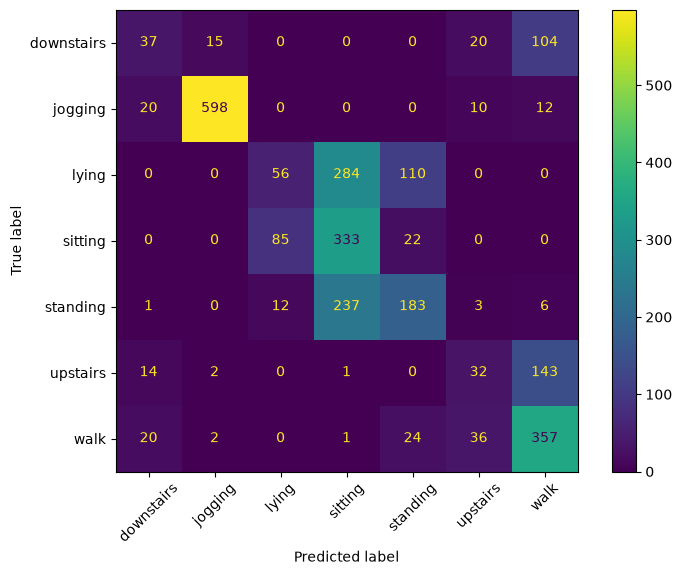

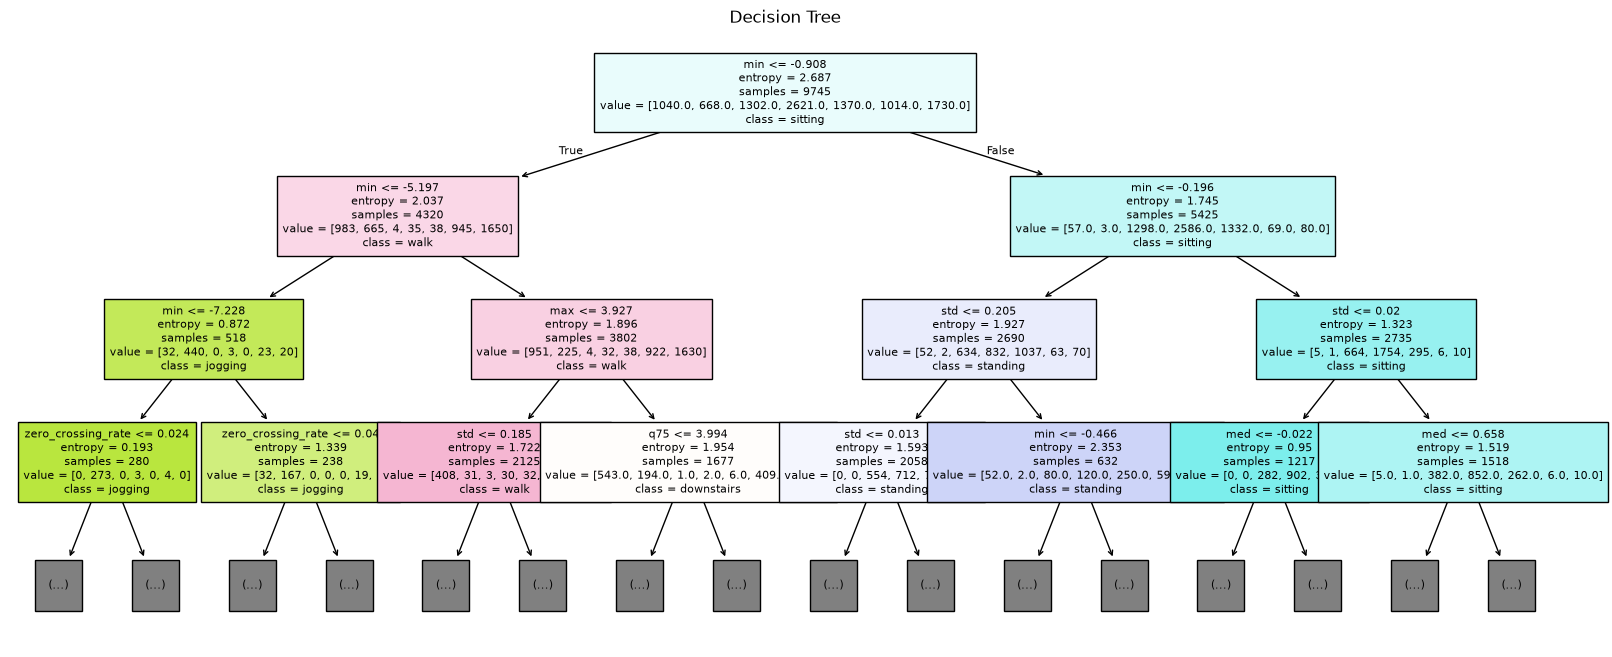

In [12]:
# roughly similar flow as previous section

########################### TODO ##########################
from sklearn.ensemble import RandomForestClassifier

# Default hyperparameters: train on Class_Data, test on Sample_Data
dt2_default, cm, class_split_acc_default = train_decision_tree(class_frames, features=FEATURES)
sample_acc_default2, pred = evaluate(dt2_default, sample_frames, FEATURES)

# Grid search (choose by the Class_Data test split only)
best_acc2, best_depth2, best_crit2 = grid_search_tree(class_frames, FEATURES)
print("Best hyperparameters:", best_depth2, best_crit2, "Class test accuracy:", best_acc2)

# Train the best model and evaluate on Sample_Data
dt2, cm, class_split_acc_best = train_decision_tree(class_frames, max_depth=best_depth2, criterion=best_crit2, features=FEATURES)
sample_acc_best2, pred2 = evaluate(dt2, sample_frames, FEATURES)

# Confusion matrix on Sample_Data
ConfusionMatrixDisplay.from_predictions(sample_frames['activity'], pred2, labels=dt2.classes_, xticks_rotation=45)
plt.show()

# Visualize the tree
viz_tree(dt2, class_frames[FEATURES], list(dt2.classes_))


**For the data in the dataset:**

| Hyperparameters | Accuracy (Class_Data test split) | Accuracy (Sample_Data) |
|-|-|-|
| Default (max_depth=5, criterion='entropy') | 0.5521 | 0.5964 |
| Best (max_depth=10, criterion='entropy') | 0.5691 | 0.5741 |


#### 🛑 Interpretation of the results

The default decision tree achieved about 55.2% accuracy on the Class_Data test split and 59.6% on Sample_Data. The grid search (choosing only by the Class_Data test split) picked max_depth=10 with criterion='entropy', which reached 56.9% on the Class_Data split but only 57.4% on Sample_Data. These scores are well above chance (about 14% for 7 classes) but far below the 70–74% the Sample_Data models reached on their own split in Classification1. This suggests that Class_Data is the harder, more varied dataset, and that the model still carries over only partly to Sample_Data.

Some activities are much easier to distinguish than others. Jogging is classified best in both evaluations (f1 of 0.77–0.80 on the Class_Data split and 0.95 on Sample_Data), because it is fast and intense. Sitting and walk are recognized reasonably well, with recall between 0.76 and 0.93, but part of that is because the model tends to predict them for other classes (sitting precision is only 0.39–0.42 and walk precision 0.57–0.58). Upstairs is the hardest class: the default model had zero precision and recall for it on both datasets, and the tuned model only reached a recall of 0.16–0.17. Lying is also hard, with a recall of 0.08 on the Class_Data split and 0.02 on Sample_Data for the default model (0.33 and 0.12 for the tuned model). Both are consistent with similar activities being confused: lying with sitting and standing, which are all almost motionless, and upstairs with walk and downstairs.

Hyperparameter tuning improved accuracy on the Class_Data split by about 1.7 percentage points (55.2% to 56.9%), but accuracy on Sample_Data decreased by about 2.2 points (59.6% to 57.4%). Depth mattered: a depth of 3 was clearly too shallow (50–53%), accuracy peaked around depth 10 (about 57%), and with no depth limit it dropped to 52–53%, which suggests the tree starts to overfit. The entropy and log_loss options gave identical results, because they are the same criterion. Overall, tuning helped a little on the dataset used for selection but did not carry over to the other dataset, so the best hyperparameters for one dataset are not necessarily best for another.

## Assignment-Classification3: Testing a new Classifier Performance (Train: Sample_Data, Test: Class_Data)

Repeat section Assignment-Classification1 with a different classifier, using the same window length and feature set. It could be Random Forest, kNN, Logistic regression, or any other classifier of your choice (add its import to the imports block). Tune its key hyperparameters the same way as in Classification1. Finally compare it with the decision tree in the assignment-classification1 section (model exploration, exploration report §2).

Note: kNN, Logistic Regression, and SVM are sensitive to feature scale, so standardize the features first (e.g., `make_pipeline(StandardScaler(), KNeighborsClassifier())`).

n_estimators = 50  max_depth = 5  accuracy = 0.723
n_estimators = 50  max_depth = 10  accuracy = 0.7734
n_estimators = 50  max_depth = None  accuracy = 0.7662
n_estimators = 100  max_depth = 5  accuracy = 0.7338
n_estimators = 100  max_depth = 10  accuracy = 0.7734
n_estimators = 100  max_depth = None  accuracy = 0.7758
n_estimators = 200  max_depth = 5  accuracy = 0.735
n_estimators = 200  max_depth = 10  accuracy = 0.7674
n_estimators = 200  max_depth = None  accuracy = 0.7758
Best hyperparameters: n_estimators = 100 max_depth = None Sample test accuracy: 0.7757793764988009
              precision    recall  f1-score   support

  downstairs       0.34      0.35      0.35      1478
     jogging       0.68      0.83      0.75       950
       lying       0.20      0.36      0.26      1813
     sitting       0.53      0.22      0.31      3779
    standing       0.40      0.59      0.48      1966
    upstairs       0.28      0.23      0.25      1458
        walk       0.49      0.46     

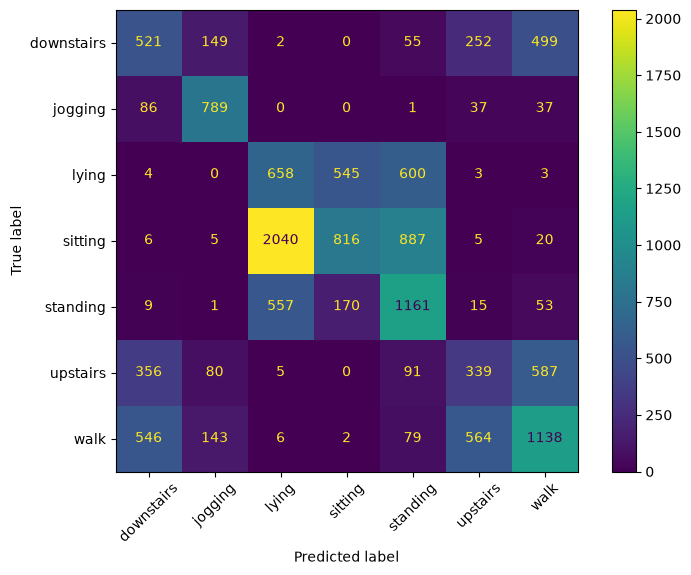

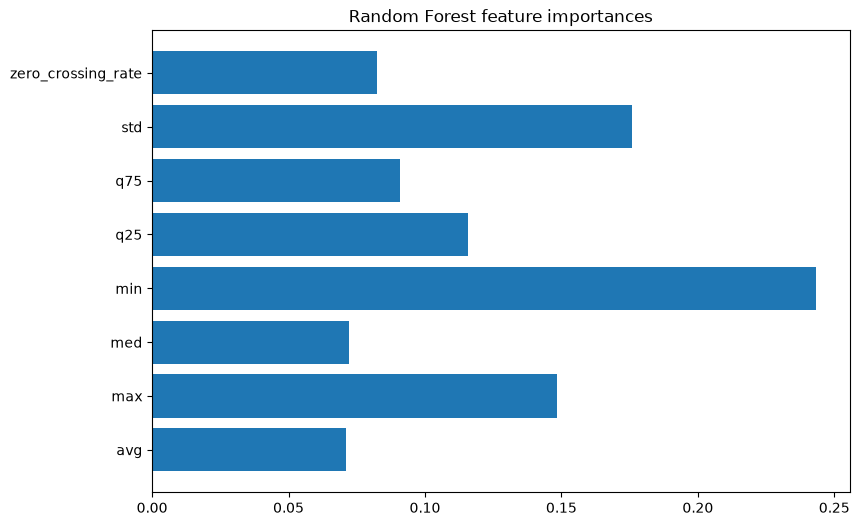

In [13]:
# Hints, step by step:
# Write a code for evaluation and training the new classifier
# Train the new classifier
# Display the confusion matrix
# Visualize the model if it makes sense (a tree, or feature importances for a forest)
# Evaluate the model on class dataset

########################### TODO ##########################

# New classifier: Random Forest (many decision trees voting together)
def train_forest(frames, n_estimators=100, max_depth=None, features=None):
    if features is None:
        features = feature_columns(frames)
    X = frames[list(features)]
    y = frames['activity']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42).fit(X_train, y_train)
    acc = model.score(X_test, y_test)
    return model, acc

def grid_search_forest(frames, features):
    best_acc, best_n, best_depth = -1, None, None
    for n in [50, 100, 200]:
        for depth in [5, 10, None]:
            m, acc = train_forest(frames, n_estimators=n, max_depth=depth, features=features)
            print("n_estimators =", n, " max_depth =", depth, " accuracy =", round(acc, 4))
            if acc > best_acc:
                best_acc, best_n, best_depth = acc, n, depth
    return best_acc, best_n, best_depth

# Grid search on Sample_Data (choose by its own test split)
rf_acc, rf_n, rf_depth = grid_search_forest(sample_frames, FEATURES)
print("Best hyperparameters: n_estimators =", rf_n, "max_depth =", rf_depth, "Sample test accuracy:", rf_acc)

# Train the best model, evaluate on Class_Data
rf1, rf1_sample_acc = train_forest(sample_frames, rf_n, rf_depth, FEATURES)
rf1_class_acc, rf1_pred = evaluate(rf1, class_frames, FEATURES)

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(class_frames['activity'], rf1_pred, labels=rf1.classes_, xticks_rotation=45)
plt.show()

# Feature importances
plt.barh(FEATURES, rf1.feature_importances_)
plt.title('Random Forest feature importances')
plt.show()


**For the data in the dataset:**

| Hyperparameters | Accuracy (Sample_Data test split) | Accuracy (Class_Data) |
|-|-|-|
| Best (n_estimators=100, max_depth=None) | 0.7758 | 0.3895 |


#### 🛑 Interpretation of the results and comparison to the decision tree.
The Random Forest achieved about 77.6% accuracy on the Sample_Data test split using the best hyperparameters, n_estimators=100 and max_depth=None (chosen using only the Sample_Data split). When evaluated on Class_Data, its accuracy was about 39.0%. Limiting the trees to depth 5 was clearly worse (72–74%), while depths of 10 and None gave 77–78%, and the number of trees (50, 100 or 200) made almost no difference.

Compared with the tuned decision tree from Classification 1 (73.9% on the Sample_Data split and 38.7% on Class_Data), the Random Forest was about 3.7 percentage points better on the Sample_Data split but only about 0.2 points better on Class_Data, which is not a meaningful difference. A forest combines many trees, which reduces the overfitting of a single tree, but on Class_Data the main problem is the difference between the datasets, not the classifier.

The gain was not equal across classes. Compared with the tuned tree on Class_Data, the forest improved recall for downstairs (0.30 to 0.35), jogging (0.78 to 0.83) and upstairs (0.18 to 0.23), and slightly for sitting (0.20 to 0.22). It lowered recall for walk (0.54 to 0.46) and lying (0.38 to 0.36), and left standing unchanged (0.59). Lying, sitting, upstairs and downstairs are still poorly recognized (f1 between 0.25 and 0.35), which is consistent with similar activities being confused, since gravity-removed magnitude makes lying, sitting and standing look alike and the three walking classes share a similar rhythm. Look at the confusion matrix and the feature-importance chart to say which features the forest relies on most.

## Assignment-Classification4: Testing a new Classifier Performance (Train: Class_Data, Test: Sample_Data)

Repeat section Assignment-Classification2 with your new classifier. Also, compare it with the decision tree in the assignment-classification2 section. Did the better model help all classes equally, or did the gain concentrate on specific classes?

n_estimators = 50  max_depth = 5  accuracy = 0.5444
n_estimators = 50  max_depth = 10  accuracy = 0.5971
n_estimators = 50  max_depth = None  accuracy = 0.5985
n_estimators = 100  max_depth = 5  accuracy = 0.5444
n_estimators = 100  max_depth = 10  accuracy = 0.6033
n_estimators = 100  max_depth = None  accuracy = 0.6047
n_estimators = 200  max_depth = 5  accuracy = 0.5454
n_estimators = 200  max_depth = 10  accuracy = 0.6007
n_estimators = 200  max_depth = None  accuracy = 0.6
Best hyperparameters: n_estimators = 100 max_depth = None Class test accuracy: 0.6047402441943979
              precision    recall  f1-score   support

  downstairs       0.47      0.47      0.47       176
     jogging       0.98      0.99      0.99       640
       lying       0.32      0.16      0.21       450
     sitting       0.42      0.73      0.53       440
    standing       0.62      0.50      0.56       442
    upstairs       0.32      0.15      0.20       192
        walk       0.63      0.74      0

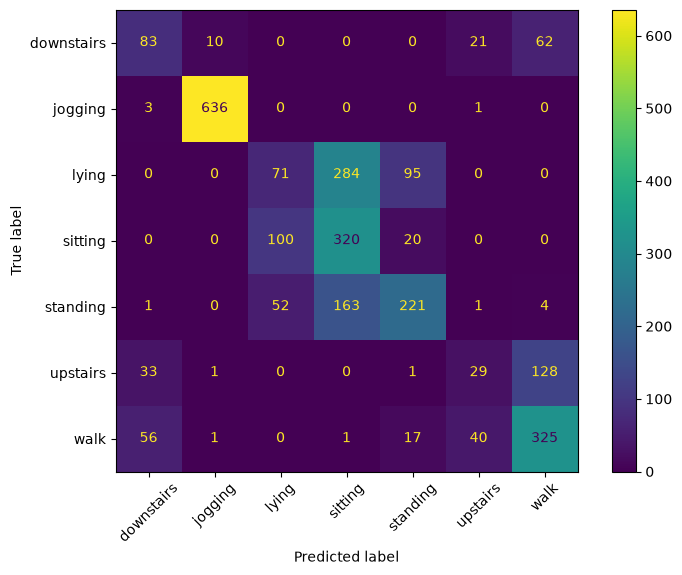

In [14]:
# roughly similar flow as previous section

########################### TODO ##########################

# Grid search on Class_Data (choose by its own test split)
rf_acc2, rf_n2, rf_depth2 = grid_search_forest(class_frames, FEATURES)
print("Best hyperparameters: n_estimators =", rf_n2, "max_depth =", rf_depth2, "Class test accuracy:", rf_acc2)

# Train the best model, evaluate on Sample_Data
rf2, rf2_class_acc = train_forest(class_frames, rf_n2, rf_depth2, FEATURES)
rf2_sample_acc, rf2_pred = evaluate(rf2, sample_frames, FEATURES)

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(sample_frames['activity'], rf2_pred, labels=rf2.classes_, xticks_rotation=45)
plt.show()


**For the data in the dataset:**

| Hyperparameters | Accuracy (Class_Data test split) | Accuracy (Sample_Data) |
|-|-|-|
| Best (n_estimators=100, max_depth=None) | 0.6047 | 0.6061 |


#### 🛑 Interpretation of the results and comparison to the decision tree.

The Random Forest achieved about 60.5% accuracy on the Class_Data test split using the best hyperparameters, n_estimators=100 and max_depth=None (chosen using only the Class_Data split). When evaluated on Sample_Data, it achieved about 60.6% accuracy. Limiting the trees to depth 5 gave only about 54%, while depths of 10 and None gave 60–60.5%, and the number of trees (50, 100 or 200) made little difference.

Compared with the tuned Decision Tree from Classification2 (56.9% on the Class_Data split and 57.4% on Sample_Data), the Random Forest was better by about 3.6 percentage points on Class_Data and about 3.2 points on Sample_Data. Unlike in Classification3, the forest's advantage carries over to the other dataset here, which suggests that training on the more varied Class_Data gives the forest something to generalize from. A forest averages many trees, which reduces the overfitting of a single deep tree.

The improvement did not help all classes equally. On Sample_Data, the forest improved recall most for downstairs (0.21 to 0.47), and also for standing (0.41 to 0.50), jogging (0.93 to 0.99) and lying (0.12 to 0.16). It lowered recall for walk (0.81 to 0.74), sitting (0.76 to 0.73) and upstairs (0.17 to 0.15). So the gain was concentrated in downstairs and standing, while a few classes got slightly worse. Lying and upstairs are still poorly recognized (recall 0.16 and 0.15), which is consistent with lying being confused with the other still postures and upstairs with walk and downstairs.

###  Assignment: Function 4: predict_recordings(model, frames, features)

So far every number is a **window** accuracy. A real app labels a whole recording, so aggregate the window predictions of each recording into one label (exploration report §3).

**Hints and Instructions:**
- The function takes as arguments:
  - `model`: a trained classifier
  - `frames`: a feature DataFrame with the `activity` and `recording` columns
  - `features`: the feature columns the model was trained on
- The function will perform the following:
  - Predict the label of every window
  - Group the predictions by `recording` and take the most common label (majority vote). You may also try confidence-weighting with `model.predict_proba`.
  - Return a DataFrame with one row per recording and the columns `true` and `predicted`

In [15]:
def predict_recordings(model, frames, features=None):
    # By default, use the same columns the model was trained on
    if features is None:
        features = getattr(model, 'feature_names_in_', feature_columns(frames))

    ######## TODO ###############
    frames = frames.copy()
    frames['pred'] = model.predict(frames[list(features)])   # label of every window

    # majority vote: most common predicted label in each recording
    recordings = frames.groupby(['activity', 'recording'])['pred'].agg(lambda s: s.mode()[0]).reset_index()
    recordings = recordings.rename(columns={'activity': 'true', 'pred': 'predicted'})
    #############################

    return recordings

In [16]:
rec = predict_recordings(dt2, sample_frames, FEATURES)
print(rec.head())
print(rec.columns.tolist())
print(len(rec), "recordings; unique files:", sample_frames['recording'].nunique())

         true recording predicted
0  downstairs   026.csv      walk
1  downstairs   027.csv      walk
2  downstairs   028.csv      walk
3  downstairs   029.csv      walk
4  downstairs   030.csv      walk
['true', 'recording', 'predicted']
35 recordings; unique files: 5


## Assignment-Classification5: Recording-Level Predictions

Use `predict_recordings` with your best decision tree and your best new classifier from Classification2 and Classification4 (trained on Class_Data), on Sample_Data. Then do the same for your models from Classification1 and Classification3 (trained on Sample_Data), on Class_Data.

1. **Fill up** this table.

2. **Interpretation of the results**: Does aggregating help? For which classes? When can majority vote make things worse?

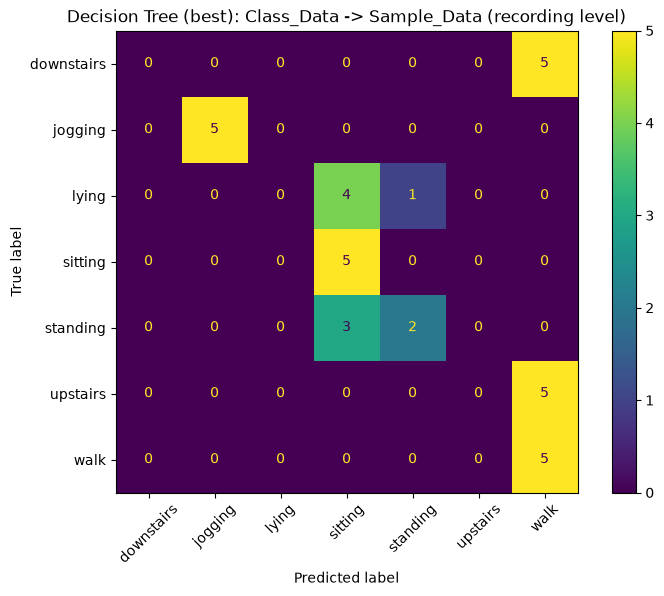

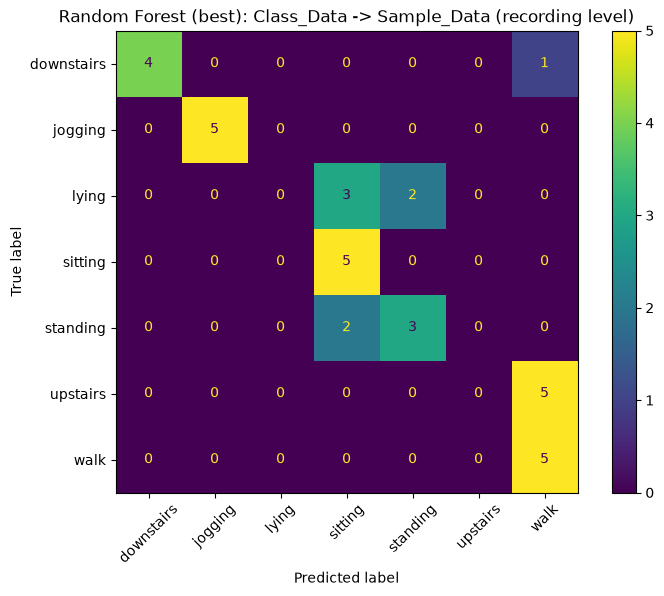

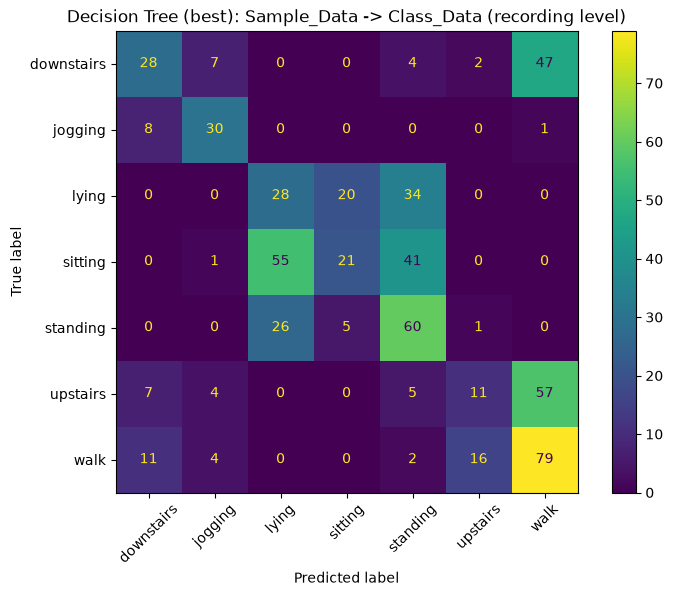

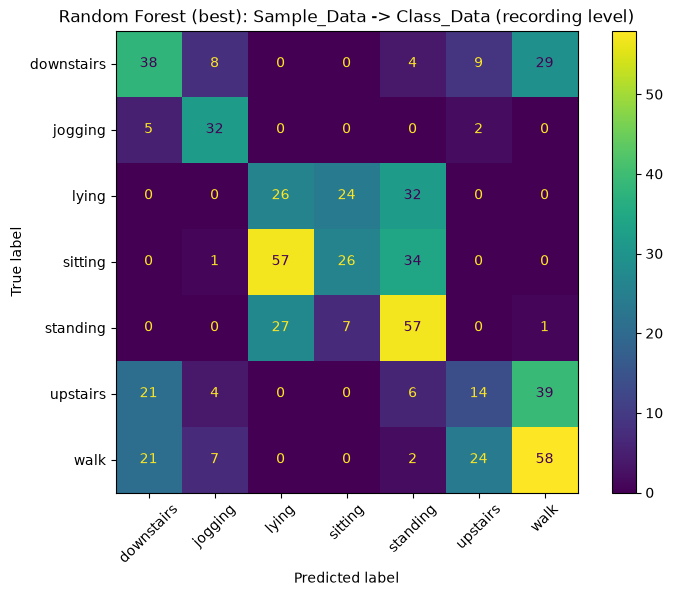

,Model,Train -> Test,Window accuracy,Recording accuracy
0,Decision Tree (best),Class_Data -> Sample_Data,0.5741,0.4857
1,Random Forest (best),Class_Data -> Sample_Data,0.6061,0.6286
2,Decision Tree (best),Sample_Data -> Class_Data,0.3872,0.4179
3,Random Forest (best),Sample_Data -> Class_Data,0.3895,0.4081


In [17]:
# Hints, step by step:
# Call predict_recordings for each model and test set
# Recording-level accuracy = (recordings['true'] == recordings['predicted']).mean()
# Display a confusion matrix of the recording-level predictions

########################### TODO ##########################
# Execution Code

rows = []   # one row per model

def run(name, direction, model, test_frames, window_acc):
    rec = predict_recordings(model, test_frames, FEATURES)
    rec_acc = (rec['true'] == rec['predicted']).mean()
    rows.append([name, direction, round(window_acc, 4), round(rec_acc, 4)])
    ConfusionMatrixDisplay.from_predictions(rec['true'], rec['predicted'], xticks_rotation=45)
    plt.title(f"{name}: {direction} (recording level)")
    plt.show()

run('Decision Tree (best)', 'Class_Data -> Sample_Data', dt2, sample_frames, sample_acc_best2)
run('Random Forest (best)', 'Class_Data -> Sample_Data', rf2, sample_frames, rf2_sample_acc)
run('Decision Tree (best)', 'Sample_Data -> Class_Data', dt1, class_frames, class_acc_best)
run('Random Forest (best)', 'Sample_Data -> Class_Data', rf1, class_frames, rf1_class_acc)

# Copy these numbers into the markdown table below
pd.DataFrame(rows, columns=['Model', 'Train -> Test', 'Window accuracy', 'Recording accuracy'])


**For the data in the dataset:**

| Model | Train → Test | Window accuracy | Recording accuracy |
|-|-|-|-|
| Decision Tree (best) | Class_Data → Sample_Data | 0.5741 | 0.4857 |
| Random Forest (best) | Class_Data → Sample_Data | 0.6061 | 0.6286 |
| Decision Tree (best) | Sample_Data → Class_Data | 0.3872 | 0.4179 |
| Random Forest (best) | Sample_Data → Class_Data | 0.3895 | 0.4081 |


#### 🛑 Interpretation of the results

Aggregating window predictions into one label per recording using majority vote helped in three of the four evaluations, but not for every model. For the models trained on Sample_Data and tested on Class_Data, recording-level accuracy improved for both the Decision Tree (38.72% to 41.79%) and the Random Forest (38.95% to 40.81%). For the Random Forest trained on Class_Data, it improved from 60.61% to 62.86%. For the Decision Tree trained on Class_Data, it got worse, from 57.41% to 48.57%.

Majority voting helps when window errors are scattered. Individual windows can be misclassified because of noise or short movements, but the most common prediction across a recording is usually correct. It makes things worse when a model is consistently wrong for a whole recording, because the vote then locks in that error instead of averaging it out. That is what happened with the Decision Tree trained on Class_Data. The first five downstairs recordings are all labelled walk, so a class that was already confused with walk at the window level loses every vote. Majority vote can also hurt when an activity changes within a recording, or when two activities are confused with each other in a consistent way (for example, lying and sitting).

Two cautions apply to these numbers. First, Sample_Data has only 35 recordings, so each recording is worth about 2.9 percentage points, and the 8.8-point drop for the Decision Tree is only 3 recordings. Second, recording-level accuracy on Class_Data is still only 41–42%, so aggregation cannot fix the dataset differences that limit the window-level results. Recording-level confusion matrices would show which classes benefit from voting.

## Assignment-Failure Analysis (for exploration report §4 and §5)

Pick your final pipeline (exploration report §3) and look at where it fails.

1. From its confusion matrix, find the **top 2 failure modes** (the largest off-diagonal cells, e.g., upstairs predicted as walk).
2. For each failure mode, use the `recording` column to find a recording or window where the failure is clear. Plot its trace (`filtered_accel_mag` over time) and compare its feature values to the typical (median) feature values of the correct class and of the predicted class.
3. Use these figures in §5 of your exploration report, and decide whether each failure is a **feature** problem or a **model** problem.

            downstairs  jogging  lying  sitting  standing  upstairs  walk
downstairs          83       10      0        0         0        21    62
jogging              3      636      0        0         0         1     0
lying                0        0     71      284        95         0     0
sitting              0        0    100      320        20         0     0
standing             1        0     52      163       221         1     4
upstairs            33        1      0        0         1        29   128
walk                56        1      0        1        17        40   325
=== Failure: lying predicted as sitting ( 284 windows ) ===
Recording: 027.csv


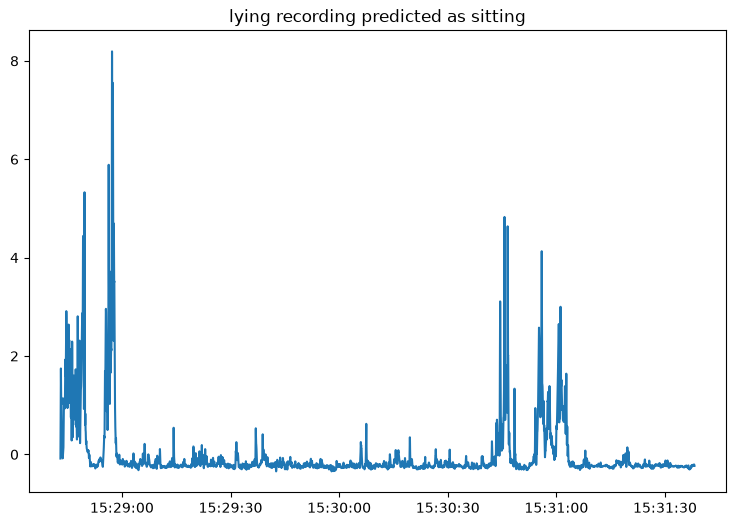

                    failing window  typical lying  typical sitting
avg                      -0.201183      -0.044093        -0.011712
max                      -0.084400       0.044314         0.045274
med                      -0.219133      -0.051209        -0.015794
min                      -0.285947      -0.111875        -0.057065
q25                      -0.241515      -0.074711        -0.031295
q75                      -0.151890      -0.029410         0.001943
std                       0.054652       0.037039         0.026888
zero_crossing_rate        0.000000       0.009804         0.019704
=== Failure: standing predicted as sitting ( 163 windows ) ===
Recording: 027.csv


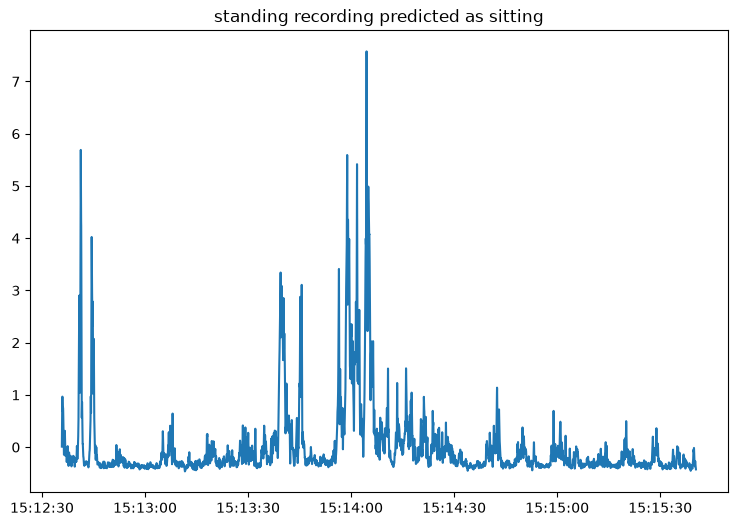

                    failing window  typical standing  typical sitting
avg                       0.003275         -0.071738        -0.011712
max                       0.777700          0.227003         0.045274
med                      -0.090665         -0.096012        -0.015794
min                      -0.359111         -0.212208        -0.057065
q25                      -0.167211         -0.145336        -0.031295
q75                       0.023700         -0.013394         0.001943
std                       0.292063          0.121132         0.026888
zero_crossing_rate        0.024631          0.019608         0.019704


In [18]:
# Hints, step by step:
# Find misclassified windows: frames[pred != frames['activity']]
# Pick one recording, reload its CSV, apply calc_magnitude and remove_noise, and plot filtered_accel_mag
# Compare: frames.groupby('activity')[FEATURES].median() vs the feature values of the failing window

########################### TODO ##########################

# Final pipeline = Random Forest trained on Class_Data, tested on Sample_Data (rf2)
true = sample_frames['activity']
pred = rf2.predict(sample_frames[FEATURES])

# 1. Find the 2 biggest mistakes in the confusion matrix
cm = confusion_matrix(true, pred, labels=rf2.classes_)
print(pd.DataFrame(cm, index=rf2.classes_, columns=rf2.classes_))   # full matrix, for section 4
np.fill_diagonal(cm, 0)
biggest = np.argsort(cm, axis=None)[::-1][:2]

typical = sample_frames.groupby('activity')[FEATURES].median()

for pos in biggest:
    i, j = np.unravel_index(pos, cm.shape)
    true_label, wrong_label = rf2.classes_[i], rf2.classes_[j]
    if cm[i, j] == 0:
        continue
    print("=== Failure:", true_label, "predicted as", wrong_label, "(", cm[i, j], "windows ) ===")

    bad = sample_frames[(true == true_label) & (pred == wrong_label)].iloc[0]
    print("Recording:", bad['recording'])

    path = glob.glob(os.path.join('./data/Sample_Data', true_label, bad['recording']))[0]
    data = pd.read_csv(path, parse_dates=['time'])
    rate = 1 / data['time'].diff().dt.total_seconds().median()
    data = remove_noise(calc_magnitude(data), rate)
    plt.plot(data['time'], data['filtered_accel_mag'])
    plt.title(f"{true_label} recording predicted as {wrong_label}")
    plt.savefig(f"failure_{true_label}_to_{wrong_label}.png")
    plt.show()

    compare = pd.DataFrame({'failing window': bad[FEATURES].astype(float),
                            f'typical {true_label}': typical.loc[true_label],
                            f'typical {wrong_label}': typical.loc[wrong_label]})
    print(compare)
